# Boundary stabilization of a sedimentation front by forwarding

Companion notebook to the paper. It reproduces, from scratch, every number of
Section 6: the operating point, the forwarding design, the small-gain condition
and the constants of the stability certificate, the exact closed-loop spectrum,
and the two data figures (the stationary profile, Figure 3 of the extended
version; the closed-loop scenarios, Figure 3 of the paper and Figure 4 of the
extended version).

Running time is about three minutes on a free Colab CPU. Nothing here needs a
GPU. The operating point is defined by eight physical constants. The only data
files are the nonlinear simulations, stored because they take about ten
minutes each; section 8 can recompute them.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Vincent69410/sedimentation-forwarding/blob/main/notebooks/worked_example.ipynb)

## 0. Setup

On Colab, the cell below downloads the code from GitHub, or brings an earlier
download up to date. Locally, it does nothing.

In [1]:
import os, sys, subprocess

REPO = "https://github.com/Vincent69410/sedimentation-forwarding.git"
if "google.colab" in sys.modules:
    if os.path.isdir("sedimentation-forwarding"):
        # an earlier session of this runtime may have left an old copy
        subprocess.run(["git", "-C", "sedimentation-forwarding", "pull", "-q", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO], check=True)
    sys.path.insert(0, "sedimentation-forwarding")
else:
    sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import sedimentation_forwarding as sf

if not hasattr(sf, "scenarios"):
    raise RuntimeError("An old version of the code is still loaded. "
                       "Use Runtime > Restart session, then Run all.")
np.seterr(all="ignore")
print("sedimentation_forwarding", sf.__version__)

sedimentation_forwarding 1.2.0


## 1. The operating point

A column of depth $z_b = 1$ m is fed at the top with a suspension of
polystyrene beads, $\rho_s = 1050\ \mathrm{kg/m^3}$, of diameter $2$ mm, at the
solid fraction $\varepsilon_{in} = 0.11$, and drained at the bottom by a pump
whose velocity $v_m$ is the control. The sediment bed is $20$ cm thick.

Beads nearly matched in density to water are chosen on purpose. The margin in
the small-gain condition is governed by the apparent gravity
$K = g(\rho_s - \rho_f)/\rho_s$, which is thirteen times smaller here than for
a mineral grain, and that is what allows a bed of $20$ cm rather than $2$ cm.

Everything else follows. The relaxation rate $\gamma$ is a parameter of the
model, not a drag law: it is fixed by requiring that the free-settling velocity
$K/\gamma$ equal the terminal velocity of an isolated bead. Above the random
loose packing fraction $\varepsilon_c = 0.55$ the beads are in contact and
carry an effective stress, taken as a power law of exponent $n_s = 5$ and scale
$\sigma_0 = 10^5$ Pa.

In [2]:
P = sf.illustrative_example()   # solves the shooting problem and the pole equation

rho_s, d = 1050.0, 2e-3
v0 = sf.examples.terminal_velocity(rho_s, d)
print(f"K          = {P.K:.4f} m/s^2")
print(f"v_0        = {v0:.5e} m/s   (Re = {sf.examples.reynolds():.1f})")
print(f"gamma      = {P.gam:.2f} s^-1")
print(f"eps_in     = {P.eps_in:.4f}")
print(f"bed L      = {P.zb - P.zs:.3f} m")
print(f"bed renewal time = {(P.zb - P.zs) * P.ep / P.fs:.1f} s")

K          = 0.4671 m/s^2
v_0        = 3.07701e-02 m/s   (Re = 61.5)
gamma      = 15.18 s^-1
eps_in     = 0.1100
bed L      = 0.200 m
bed renewal time = 26.0 s


The physically meaningful stiffness is not $\sigma_0$ but the compressive
modulus it produces at the operating point, $\rho_s c_s^2$, and the load the bed
actually carries is its buoyant weight.

In [3]:
modulus = rho_s * P.cs[0] ** 2
weight = (rho_s - 1000.0) * 9.81 * P.e.mean() * (P.zb - P.zs)
print(f"compressive modulus rho_s cs^2 = {modulus:.3e} Pa  ({modulus/1e6:.3f} MPa)")
print(f"stress at the base of the bed  = {float(P.S(P.e[-1])) * rho_s:.1f} Pa")
print(f"buoyant weight of the bed      = {weight:.1f} Pa")
print(f"solids loading                 = {P.eps_in * P.lam * rho_s * 3.6:.1f} t/m2/h")

compressive modulus rho_s cs^2 = 9.091e+05 Pa  (0.909 MPa)
stress at the base of the bed  = 54.1 Pa
buoyant weight of the bed      = 54.0 Pa
solids loading                 = 16.0 t/m2/h


## 2. Table 1: the design

The underflow $v_m^*$ comes from a scalar shooting; the design then evaluates
the interface gain $\mathbf{G}_o$, solves the pole equation $c = \mathcal{F}(c)$ by a bracketing root finder
and builds the Sylvester kernel.

In [4]:
rows = [
    ("Underflow velocity (shooting)",            "v_m*",        P.vm,       "m/s"),
    ("Free-settling speed",                      "lambda",      P.lam,      "m/s"),
    ("Interface jump",                           "[eps*]",      P.jump,     "-"),
    ("Compression eigenvalue lambda_3 at zs*",   "l3(zs*)",     P.l3s,      "m/s"),
    ("Compression eigenvalue lambda_4 at zs*",   "l4(zs*)",     P.l4s,      "m/s"),
    ("Compression eigenvalue lambda_3 at zb",    "l3(zb)",      P.l3b,      "m/s"),
    ("Compression eigenvalue lambda_4 at zb",    "l4(zb)",      P.l4b,      "m/s"),
    ("Interface reflection coefficient",         "-k^2",        -P.k ** 2,  "-"),
    ("Geometric decay ceiling",                  "mu2bar",      P.mu2bar,   "1/m"),
    ("Free-settling transit",                    "T_1",         P.zs/P.lam, "s"),
    ("Transmission pole",                        "c*",          P.cstar,    "1/s"),
    ("Non-resonance functional",                 "Delta_z",     P.Dz,       "-"),
    ("Velocity factor",                          "gamma_v",     P.gv,       "-"),
    ("Input gain",                               "G",           P.G,        "-"),
]
for name, sym, val, unit in rows:
    print(f"{name:<42}{sym:>10}  {val: .6e}  {unit}")

Underflow velocity (shooting)                   v_m*   7.691489e-03  m/s
Free-settling speed                           lambda   3.846160e-02  m/s
Interface jump                                [eps*]   4.400002e-01  -
Compression eigenvalue lambda_3 at zs*       l3(zs*)   2.943220e+01  m/s
Compression eigenvalue lambda_4 at zs*       l4(zs*)  -2.941682e+01  m/s
Compression eigenvalue lambda_3 at zb         l3(zb)   2.943855e+01  m/s
Compression eigenvalue lambda_4 at zb         l4(zb)  -2.942317e+01  m/s
Interface reflection coefficient                -k^2  -9.989548e-01  -
Geometric decay ceiling                       mu2bar   1.306916e-03  1/m
Free-settling transit                            T_1   2.079996e+01  s
Transmission pole                                 c*  -5.184904e-06  1/s
Non-resonance functional                     Delta_z   1.999602e+00  -
Velocity factor                              gamma_v   9.999326e-01  -
Input gain                                         G   1.0000

## 3. The small-gain condition

The small-gain condition is a joint feasibility problem in the weights of the
Lyapunov functional, and must be solved as one. `best` sweeps the pair
$(\mu_2, r)$ over the window where the boundary dissipation coefficients
$d_1, d_4$ are positive, the other weights being sent to their useful limit.

In [5]:
b = sf.best(P, ngrid=14)

print(f"mu_2 / mu2bar = {b['mu2'] / P.mu2bar:.4f}")
print(f"r = p4/p3     = {b['r']:.6f}")
print()
print(f"alphabar      = {b['alphabar']:.4f}")
print(f"a_eta         = {b['aeta']:.4e}   (chi = {b['chi']:.3e},"
      f" J_L = {b['JL']:.3e}, I_eta = {b['Ieta']:.3e})")
print(f"a_o           = {b['ao']:.4e}   (Sigma_b = {b['Sigma_b']:.3e},"
      f" I_o = {b['Io']:.3e})")
print(f"d_1, d_4      = {b['d1']:.3e}, {b['d4']:.3e}")
print()
print(f"(a_eta + a_o) / alphabar = {b['ratio']:.4f}"
      f"    {'SATISFIED' if b['ratio'] < 1 else 'VIOLATED'}"
      f"   (factor {1 / b['ratio']:.1f} to spare)")
print(f"certified rate  beta <= {b['margin']:.4e} s^-1")

mu_2 / mu2bar = 0.9800
r = p4/p3     = 0.999989

alphabar      = 0.0753
a_eta         = 1.9847e-02   (chi = 5.185e-06, J_L = 2.066e+00, I_eta = 1.905e-04)
a_o           = 1.7069e-03   (Sigma_b = 5.818e+05, I_o = 2.934e-09)
d_1, d_4      = 3.846e+12, 3.072e-02

(a_eta + a_o) / alphabar = 0.2863    SATISFIED   (factor 3.5 to spare)
certified rate  beta <= 5.3743e-02 s^-1


$d_4$ is the difference of two nearly equal numbers, which is why the sweep is
carried out on quantities computed to twelve digits.

In [6]:
L = P.zb - P.zs
t1 = b['r'] * np.exp(-2 * b['mu2'] * L) * abs(P.l4s)
t2 = P.l3s * (1 + b['nui']) * P.k ** 2
print(f"d_4 = {t1:.8f} - {t2:.8f} = {t1 - t2:.6e}")

d_4 = 29.40142910 - 29.40144178 = -1.268369e-05


### The certificate of Table 2

With the pair $(\mu_2, r)$ of Table 2 of the extended version, $\mu_1$ and
$p_{2x}$ given by the conditions of Appendix B on $\Omega_1^*$, and
$\nu_2=\bar\alpha/10$, $\vartheta=\alpha_{sg}/4$, $\delta=1/2$, the proof of
item (iii) of the stability theorem gives the rate $\alpha_w$ and the constants
below, for $\kappa = 0.3$.

In [7]:
c = sf.certificate(P)
print(f"mu1 = {c['mu1']:.3f} 1/m, p2x = {c['p2x']:.2e}, nu2 = {c['nu2']:.3e}, theta = {c['theta']:.3e}")
print(f"sigma_u = {c['sigma_u']:.2e}, sigma_udot = {c['sigma_udot']:.2e}, b_w = {c['b_w']:.2e}")
print(f"alpha_w = {c['alpha_w']:.3e} 1/s")
print(f"rho >= {c['rho_min']:.2e},  c2/c1 = {c['c2_over_c1']:.2e},  C >= {c['C']:.2e}")
print(f"the estimate says something only after t = ln C / alpha_w = {c['t_info']:.2e} s")

mu1 = 1.369 1/m, p2x = 9.80e+14, nu2 = 7.530e-03, theta = 1.344e-02
sigma_u = 1.07e+17, sigma_udot = 3.08e+14, b_w = 9.66e+15
alpha_w = 3.107e-02 1/s
rho >= 1.70e+16,  c2/c1 = 9.81e+14,  C >= 6.88e+31
the estimate says something only after t = ln C / alpha_w = 2.36e+03 s


## 4. The characteristic determinant

We check the interface pole $c^*$ against a computation that does not use the
kernel: $c^*$ must be an eigenvalue of the open-loop generator, that is, a zero
of a $5 \times 5$ determinant built from the resolvent, with the generator
nowhere discretized. The two computations share only the stationary profile
and the propagator.

In [8]:
print(f"{'propagator steps':>18}   {'zero of det D':>22}")
for nst in (250, 500, 800):
    sp = sf.Spec(P, nst=nst)
    print(f"{nst:>18}   {np.real(sp.newton(P.cstar * 1.02)):>22.12e}")
print(f"{'fixed point':>18}   {P.cstar:>22.12e}")

  propagator steps            zero of det D
               250      -5.184904372839e-06
               500      -5.184904372830e-06


               800      -5.184904372854e-06
       fixed point      -5.184904372854e-06


## 5. Closing the loop moves that zero to $-\kappa$

The feedback is $u = \mathfrak{K} w$ with $\mathfrak{K} = -(c^* + \kappa)/G$.
The real zero of $\det D$ nearest $-\kappa$ should be $-\kappa$ exactly.

In [9]:
sp = sf.Spec(P, nst=500)
kappas = np.geomspace(3.16e-2, 1.0, 9)
err = []
for kap in kappas:
    Kg = sp.gain(kap)
    r = sp.newton(-kap * 1.00002, "forwarding", Kg)
    r = sp.newton(r, "forwarding", Kg)
    err.append(abs(np.real(r) / (-kap) - 1.0))
err = np.array(err)
for kap, e in zip(kappas, err):
    print(f"kappa = {kap:8.4f}   relative error {e:.2e}")
print(f"\nworst case: {err.max():.2e}")

kappa =   0.0316   relative error 4.66e-15
kappa =   0.0487   relative error 7.33e-15
kappa =   0.0749   relative error 5.77e-15
kappa =   0.1154   relative error 4.22e-15
kappa =   0.1778   relative error 4.66e-15
kappa =   0.2738   relative error 5.55e-15
kappa =   0.4216   relative error 1.05e-13
kappa =   0.6493   relative error 3.18e-12
kappa =   1.0000   relative error 7.39e-09

worst case: 7.39e-09


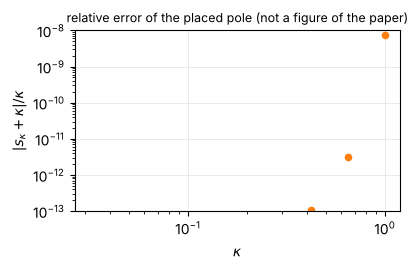

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 2.8))
ax.loglog(kappas, np.maximum(err, 1e-15), "o", color="C1", ms=4.5)
ax.set_xlabel(r"$\kappa$"); ax.set_ylabel(r"$|s_\kappa+\kappa|/\kappa$")
ax.set_ylim(1e-13, 1e-8); ax.grid(True, color="0.88", lw=0.5)
ax.set_title("relative error of the placed pole (not a figure of the paper)", fontsize=9)
fig.tight_layout(); plt.show()

## 6. No other eigenvalue to the right of $-1$

Counting zeros of $\det D$ by the argument principle on rectangular contours.
The determinant must be used raw here: any normalization of the matrix rows is
non-analytic and corrupts the winding number.

The gap is set by the relaxation rate $\gamma$ of the free-settling zone, which
is $15.2\ \mathrm{s^{-1}}$ on these beads: the delay family it carries sits
between $-1$ and $-3$, so the box is taken down to $-1$ and not further.

In [11]:
def winding(sp, Kg, re_min, re_max, im_max, npt=1600):
    """Number of zeros of det D inside the rectangle, by the argument principle."""
    t = np.linspace(0, 1, npt)
    sides = [re_min + (re_max - re_min) * t - 1j * im_max,
             re_max + 1j * (-im_max + 2 * im_max * t),
             re_max + (re_min - re_max) * t + 1j * im_max,
             re_min + 1j * (im_max - 2 * im_max * t)]
    phase = []
    for side in sides:
        for s in side:
            y1s, _, j1 = sp.omega1(s)
            phase.append(np.angle(np.linalg.det(
                sp.det_with(s, y1s, j1, "forwarding", Kg))))
    u = np.unwrap(np.array(phase))
    return (u[-1] - u[0]) / (2 * np.pi)


sp = sf.Spec(P, nst=250)
for kap in (3.16e-2, 3.16e-1):
    Kg = sp.gain(kap)
    n_right = winding(sp, Kg, -1e-9, 5.0, 30.0)
    n_band = winding(sp, Kg, -1.0, -1e-9, 30.0)
    print(f"kappa = {kap:7.4f}:  # zeros in Re s > 0 : {n_right:+.3f}"
          f"     # zeros in [-1,0] x [-30,30] : {n_band:+.3f}")

kappa =  0.0316:  # zeros in Re s > 0 : +0.000     # zeros in [-1,0] x [-30,30] : +1.000


kappa =  0.3160:  # zeros in Re s > 0 : +0.000     # zeros in [-1,0] x [-30,30] : +1.000


The single zero of the box is the placed pole. The spectral abscissa of the
closed loop is therefore exactly $-\kappa$ for $\kappa$ up to $1$, the next
family lying beyond $-1$.

## 7. The stationary profile

The stationary admissible profile; the inset shows the deviation
$\varepsilon_s^*-\varepsilon_s^*(z_s^{*+})$ on the compression zone, magnified.
The figure is drawn by `sf.figures.figure_profile`, the function that produced
the figure of the paper. The compression margin
$\varepsilon_s^*(z_s^{*+})-\varepsilon_c$ is printed below.

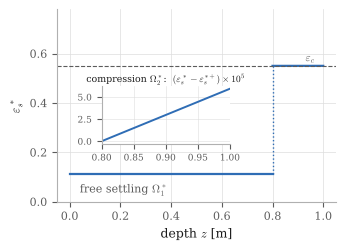

compression margin eps*(zs+) - eps_c = 1.50e-07
relative variation of eps* over the bed = 1.1e-04


In [12]:
P2 = sf.illustrative_example(Nd=2000)   # the resolution used for the figure of the paper
fig = sf.figures.figure_profile(P2)
plt.show()
print(f"compression margin eps*(zs+) - eps_c = {P2.ep - P2.eps_c:.2e}")
print(f"relative variation of eps* over the bed = {(P2.e.max() - P2.e.min()) / P2.e.mean():.1e}")

## 8. The nonlinear closed loop

The linear theory says nothing about the nonlinear plant, so we test the
feedback on it. The original $2\times2$ system is solved on the physical domain
$(0, z_b)$ by a shock-capturing scheme (finite volumes, Rusanov flux, SSP-RK2),
with $800$ cells, so $160$ in the bed: the blanket is a shock captured by the
scheme, not an unknown of the problem. At each step the state is mapped onto
the reference configuration, $Y$ is formed, and
$v_m = v_m^* + \mathfrak{K}\,(\eta - \mathbf{L}[Y])$, with $\kappa = 0.3$; the
reference ($z_s^*$, $v_m^*$, $\varepsilon_s^*$, $\mathbf{L}$, $\mathfrak{K}$) is the
equilibrium of the current set point and feed fraction.

Two scenarios, $75$ s each:

* **change of set point**: the bed goes from $20$ to $21$ cm at $t=5$ s and back
  at $t=40$ s;
* **step of the feed fraction**: $\varepsilon_{in}\to1.1\,\varepsilon_{in}$ at
  $t=5$ s, the reference being switched to the equilibrium of the new feed
  fraction. This case is not covered by the theory, which assumes
  $\varepsilon_{in}$ constant.

Each run takes about ten minutes, so both are stored in the repository. Set
`RERUN = True` to recompute them; the result is the same to the last digit.

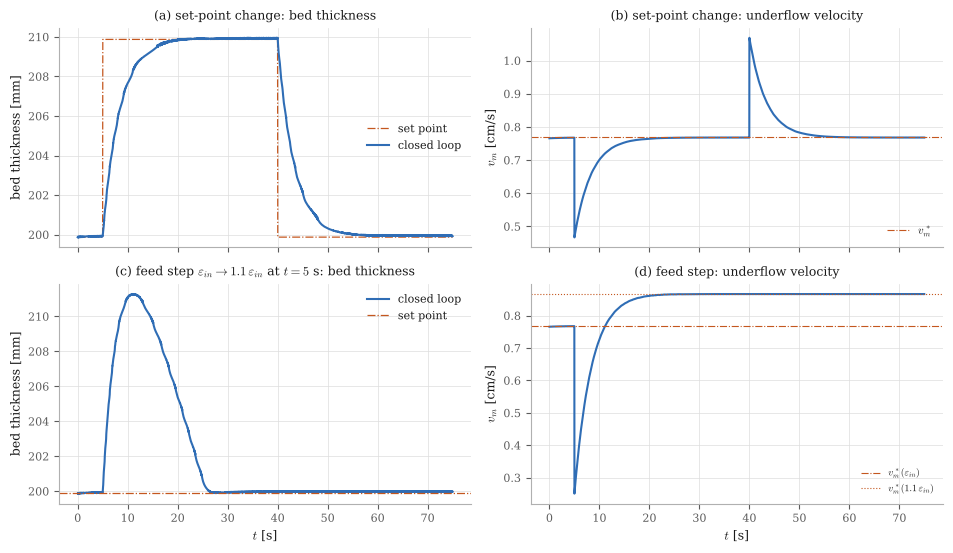

change of set point
  within 1 mm of the set point after 7.6 s (up) and 8.0 s (down); 10 exp(-kappa t) mm gives 7.7 s
  underflow between 0.467 and 1.07 cm/s
step of the feed fraction
  new v_m* = 0.868 cm/s, underflow down to 0.25 cm/s
  bed up to 211.3 mm at t = 11.1 s
  new suspension reaches the bed at t = 25.8 s; final error +0.10 mm
open-loop drift of the scheme: -15.6 micrometres/s


In [13]:
from sedimentation_forwarding import scenarios, closed_loop

RERUN = False
runs = scenarios.recompute_runs(verbose=True) if RERUN else scenarios.load_runs()

fig = sf.figures.figure_scenarios(runs)
plt.show()

s = scenarios.summary(runs)
print("change of set point")
print(f"  within 1 mm of the set point after {s['setpoint_up_within_1mm_after_s']:.1f} s (up) "
      f"and {s['setpoint_down_within_1mm_after_s']:.1f} s (down); 10 exp(-kappa t) mm gives {np.log(10)/0.3:.1f} s")
print(f"  underflow between {s['setpoint_vm_min_cm_s']:.3f} and {s['setpoint_vm_max_cm_s']:.2f} cm/s")
print("step of the feed fraction")
print(f"  new v_m* = {s['feed_vm_star_new_cm_s']:.3f} cm/s, underflow down to {s['feed_vm_min_cm_s']:.2f} cm/s")
print(f"  bed up to {s['feed_bed_max_mm']:.1f} mm at t = {s['feed_t_bed_max_s']:.1f} s")
print(f"  new suspension reaches the bed at t = {s['feed_front_arrival_s']:.1f} s; "
      f"final error {s['feed_final_error_mm']:+.2f} mm")
print(f"open-loop drift of the scheme: {closed_loop.drift() * 1e6:.1f} micrometres/s")

## 9. Explore

`settling_column` takes the physical parameters directly. The feasibility of
the small-gain condition is governed by the stiffness of the bed and by its thickness: the
cell below sweeps the stress scale.

In [14]:
print(f"{'sigma_0 [Pa]':>14}{'modulus [MPa]':>16}{'ratio':>10}")
for sigma_0 in (1e4, 3e4, 1e5, 1e6, 1e7):
    Q = sf.settling_column(sigma_0=sigma_0, Nd=500)
    if not Q.ok or Q.solve_cstar() is None:
        continue
    c = sf.best(Q, ngrid=8)   # coarser sweep than the paper
    print(f"{sigma_0:14.0e}{rho_s * Q.cs[0] ** 2 / 1e6:16.3f}{c['ratio']:10.4f}")

print()
print(f"{'bed L [cm]':>12}{'ratio':>10}")
for Lm in (0.05, 0.10, 0.20, 0.30, 0.50):
    Q = sf.settling_column(L=Lm, Nd=500)
    if not Q.ok or Q.solve_cstar() is None:
        continue
    print(f"{100*Lm:12.0f}{sf.best(Q, ngrid=8)['ratio']:10.4f}")

  sigma_0 [Pa]   modulus [MPa]     ratio


         1e+04           0.091    1.0707


         3e+04           0.273    0.5583


         1e+05           0.909    0.2863


         1e+06           9.091    0.0855


...

           5    0.0673


          10    0.1374


          20    0.2863


          30    0.4466


          50    0.8019


The condition fails below about $0.10$ MPa of compressive modulus, and above a
bed of about $60$ cm. The density contrast acts through $K$: at the same bead
diameter but $\rho_s = 2650$ the thickness limit drops to $26$ cm, and on a
$0.5$ mm mineral grain to $7$ cm.

If you use this code, please cite the paper.